# DIN leave-one-out behavior attribution

This notebook compares how the trained DIN `none`, `kar_base`, and `kar_ours` variants respond when every occurrence of one company is removed from a user's history. Each source row therefore contributes one ablation per unique history company, not one ablation per position.

The primary measure is **target margin drop**: the original correct-target margin minus the margin after removal. A positive value means the removed item supported the correct prediction. Candidate-set probability drop and logloss increase provide scale-independent supporting views. Raw target-logit changes are retained in the CSVs but are not emphasized because all candidate logits can shift together.

In [1]:
from pathlib import Path

# Editable settings
ROOT = Path.cwd()
if not (ROOT / 'leave_one_out.py').exists():
    ROOT = Path('/home/leeze/career_experiments_2')
RESULT_DIR = ROOT / 'data' / 'leave_one_out'
PREDICTION_TASK = 'company'
SPLIT = 'ood'
EXCLUDE_REMOVED_EQUALS_TARGET = False
HISTOGRAM_BINS = 50
PLOT_QUANTILES = (0.01, 0.99)  # Display clipping only; tables use all values.

ADAPTORS = ('none', 'kar_base', 'kar_ours')
COLORS = {'none': '#7f7f7f', 'kar_base': '#2878b5', 'kar_ours': '#d62728'}

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

frames = []
missing = []
for adaptor in ADAPTORS:
    path = RESULT_DIR / f'leave_one_out_{adaptor}_{PREDICTION_TASK}_{SPLIT}.csv'
    if not path.exists():
        missing.append(path)
        continue
    frame = pd.read_csv(path)
    frame['adaptor'] = adaptor
    frames.append(frame)

if missing:
    paths = '\n'.join(f'  - {path}' for path in missing)
    raise FileNotFoundError(
        'Leave-one-out results are missing. Run `python leave_one_out.py` first.\n' + paths
    )

results = pd.concat(frames, ignore_index=True)
results['removed_item_is_ood'] = (
    results['removed_item_is_ood'].astype(str).str.lower().map({'true': True, 'false': False})
).fillna(results['removed_item_is_ood'].astype(bool))
results['removed_item_group'] = np.where(
    results['removed_item_is_ood'], 'OOD history item', 'non-OOD history item'
)
if EXCLUDE_REMOVED_EQUALS_TARGET:
    results = results[results['removed_item'] != results['target_item']].copy()

required_columns = {'removed_positions', 'removed_occurrence_count'}
missing_columns = required_columns.difference(results.columns)
if missing_columns:
    raise ValueError(
        f'Results use the old position-level schema ({sorted(missing_columns)} missing). '
        'Rerun `python leave_one_out.py` to generate company-level removals.'
    )

identity_columns = ['row_index', 'removed_item', 'target_item']
duplicate_count = int(results.duplicated(['adaptor', *identity_columns]).sum())
if duplicate_count:
    raise ValueError(f'Found {duplicate_count} duplicate attribution rows.')

print(f'Loaded {len(results):,} attribution rows')
print(f'Unique source samples: {results.row_index.nunique():,}')
print(f'Unique company-level ablations: {results[identity_columns].drop_duplicates().shape[0]:,}')
print(f'Mean occurrences removed per ablation: {results.removed_occurrence_count.mean():.2f}')

Loaded 27,300 attribution rows
Unique source samples: 2,756
Unique company-level ablations: 9,100
Mean occurrences removed per ablation: 1.53


## Numerical overview

Means indicate average direction and magnitude; medians show whether the result is typical or driven by a smaller number of large changes.

In [3]:
metric_columns = [
    'target_margin_drop',
    'target_probability_drop',
    'logloss_increase',
    'rank_increase',
]
overview = (
    results.groupby(['adaptor', 'removed_item_group'], observed=True)
    .agg(
        removals=('removed_item', 'size'),
        samples=('row_index', 'nunique'),
        mean_occurrences_removed=('removed_occurrence_count', 'mean'),
        mean_margin_drop=('target_margin_drop', 'mean'),
        median_margin_drop=('target_margin_drop', 'median'),
        mean_probability_drop=('target_probability_drop', 'mean'),
        median_probability_drop=('target_probability_drop', 'median'),
        mean_logloss_increase=('logloss_increase', 'mean'),
        mean_rank_increase=('rank_increase', 'mean'),
    )
    .reindex(pd.MultiIndex.from_product(
        [ADAPTORS, ['OOD history item', 'non-OOD history item']],
        names=['adaptor', 'removed_item_group'],
    ))
)
display(overview.round(5))

removals  samples  mean_occurrences_removed  \
adaptor  removed_item_group                                                  
none     OOD history item          3171     2756                   1.69284   
         non-OOD history item      5929     2558                   1.44055   
kar_base OOD history item          3171     2756                   1.69284   
         non-OOD history item      5929     2558                   1.44055   
kar_ours OOD history item          3171     2756                   1.69284   
         non-OOD history item      5929     2558                   1.44055   

                               mean_margin_drop  median_margin_drop  \
adaptor  removed_item_group                                           
none     OOD history item              -0.00256            -0.00898   
         non-OOD history item           0.37325             0.04304   
kar_base OOD history item              -0.00334            -0.00789   
         non-OOD history item           0.35010             0.04908   
kar_ours OOD history item               0.24173             0.07436   
         non-OOD history item           0.30395             0.00734   

                               mean_probability_drop  median_probability_drop  \
adaptor  removed_item_group                                                     
none     OOD history item                    0.00893                  0.00212   
         non-OOD history item                0.04028                  0.00013   
kar_base OOD history item                    0.00921                  0.00132   
         non-OOD history item                0.02762                 -0.00079   
kar_ours OOD history item                    0.03279                  0.00030   
         non-OOD history item                0.02670                 -0.00060   

                               mean_logloss_increase  mean_rank_increase  
adaptor  removed_item_group                                               
none     OOD history item                    0.12508             0.40997  
         non-OOD history item                0.20297             0.68291  
kar_base OOD history item                    0.17662             0.49101  
         non-OOD history item                0.24759             0.79187  
kar_ours OOD history item                    0.34510             0.84011  
         non-OOD history item                0.22092             0.76691

## Mean effect of removing OOD and non-OOD history companies

Positive bars mean that removal hurts the correct prediction. Larger positive OOD bars for `kar_ours` would be consistent with that model making greater use of OOD history information, although this alone is not causal evidence that the information is semantically correct.

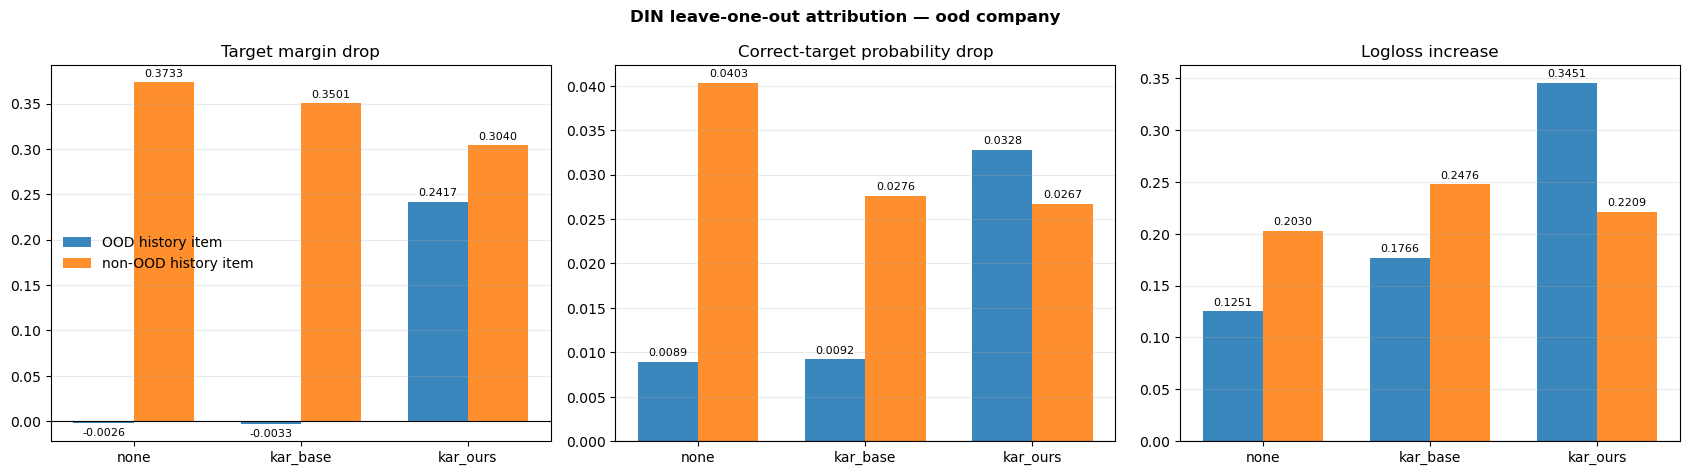

In [4]:
plot_metrics = [
    ('target_margin_drop', 'Target margin drop'),
    ('target_probability_drop', 'Correct-target probability drop'),
    ('logloss_increase', 'Logloss increase'),
]
groups = ['OOD history item', 'non-OOD history item']
x = np.arange(len(ADAPTORS))
bar_width = 0.36
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for axis, (metric, title) in zip(axes, plot_metrics):
    for group_index, group in enumerate(groups):
        means = [
            results.loc[
                (results.adaptor == adaptor) & (results.removed_item_group == group), metric
            ].mean()
            for adaptor in ADAPTORS
        ]
        offsets = x + (group_index - 0.5) * bar_width
        bars = axis.bar(offsets, means, bar_width, label=group, alpha=0.88)
        axis.bar_label(bars, fmt='%.4f', padding=3, fontsize=8)
    axis.axhline(0, color='black', linewidth=0.8)
    axis.set_xticks(x, ADAPTORS)
    axis.set_title(title)
    axis.grid(axis='y', alpha=0.25)
axes[0].legend(frameon=False)
fig.suptitle(f'DIN leave-one-out attribution — {SPLIT} {PREDICTION_TASK}', fontweight='bold')
fig.tight_layout()
plt.show()

## Distribution for OOD-company removals

The plots are clipped only for readability at the configured quantiles. The dashed line marks zero contribution.

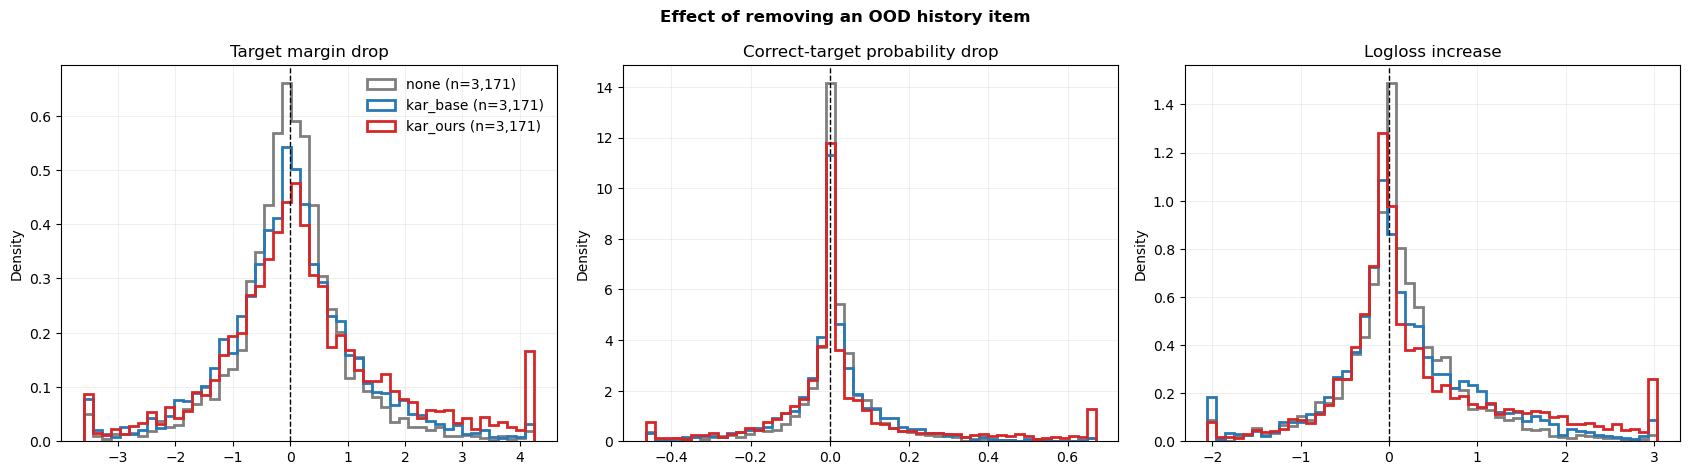

In [5]:
ood_results = results[results.removed_item_is_ood].copy()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for axis, (metric, title) in zip(axes, plot_metrics):
    finite = ood_results[metric].replace([np.inf, -np.inf], np.nan).dropna()
    lower, upper = finite.quantile(PLOT_QUANTILES).tolist()
    for adaptor in ADAPTORS:
        values = ood_results.loc[ood_results.adaptor == adaptor, metric].clip(lower, upper)
        axis.hist(
            values, bins=HISTOGRAM_BINS, density=True, histtype='step', linewidth=2,
            color=COLORS[adaptor], label=f'{adaptor} (n={len(values):,})'
        )
    axis.axvline(0, color='black', linestyle='--', linewidth=1)
    axis.set_title(title)
    axis.set_ylabel('Density')
    axis.grid(alpha=0.2)
axes[0].legend(frameon=False)
fig.suptitle('Effect of removing an OOD history item', fontweight='bold')
fig.tight_layout()
plt.show()

## Paired KAR-Ours advantage on the same OOD removals

Every point is matched by source row and removed company. A positive difference means that removing all occurrences of the OOD company affected `kar_ours` more than the comparison model under that metric.

/home/leeze/.tmp/ipykernel_1528126/1674926436.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axis.boxplot(all_differences, labels=labels, showfliers=False)
/home/leeze/.tmp/ipykernel_1528126/1674926436.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axis.boxplot(all_differences, labels=labels, showfliers=False)
/home/leeze/.tmp/ipykernel_1528126/1674926436.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axis.boxplot(all_differences, labels=labels, showfliers=False)


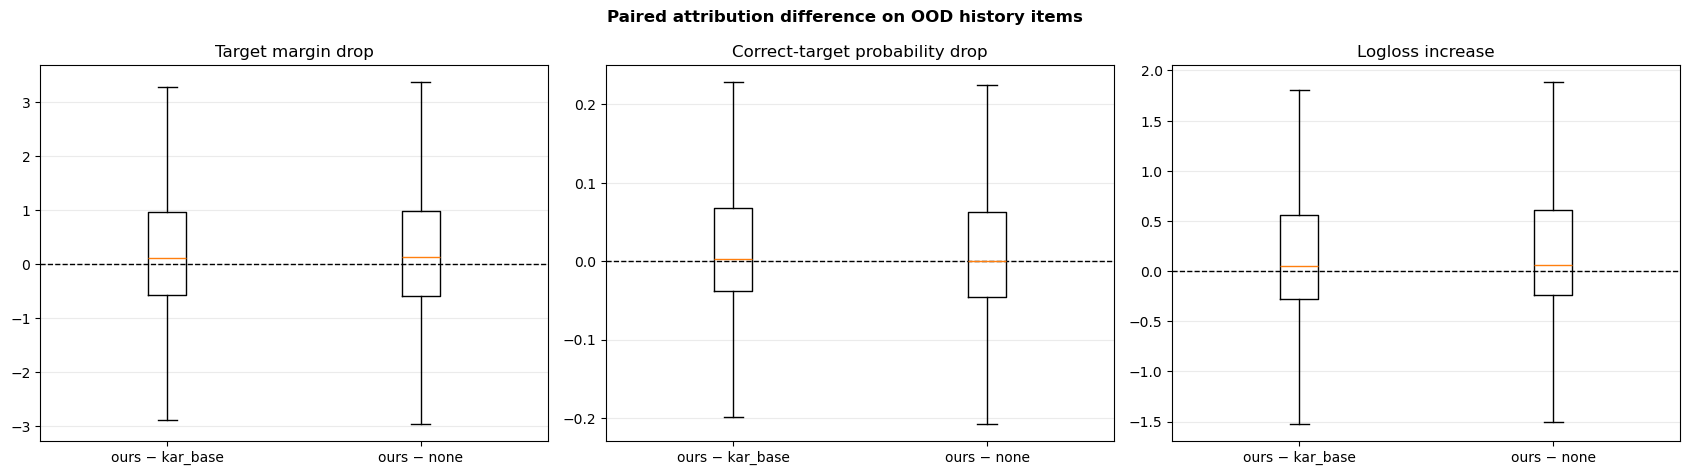

pairs  mean_difference  \
metric                  comparison                                    
target_margin_drop      kar_ours - kar_base   3171          0.24508   
                        kar_ours - none       3171          0.24430   
target_probability_drop kar_ours - kar_base   3171          0.02358   
                        kar_ours - none       3171          0.02386   
logloss_increase        kar_ours - kar_base   3171          0.16848   
                        kar_ours - none       3171          0.22001   

                                             median_difference  \
metric                  comparison                               
target_margin_drop      kar_ours - kar_base            0.10759   
                        kar_ours - none                0.13534   
target_probability_drop kar_ours - kar_base            0.00283   
                        kar_ours - none                0.00047   
logloss_increase        kar_ours - kar_base            0.05150   
                        kar_ours - none                0.05769   

                                             fraction_positive  
metric                  comparison                              
target_margin_drop      kar_ours - kar_base            0.54809  
                        kar_ours - none                0.54904  
target_probability_drop kar_ours - kar_base            0.54778  
                        kar_ours - none                0.51939  
logloss_increase        kar_ours - kar_base            0.55944  
                        kar_ours - none                0.54084

In [6]:
paired = ood_results.pivot(
    index=identity_columns, columns='adaptor', values=metric_columns
).dropna()
paired_summary_rows = []
comparisons = ('kar_base', 'none')
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for axis, (metric, title) in zip(axes, plot_metrics):
    all_differences = []
    labels = []
    for comparison in comparisons:
        difference = paired[(metric, 'kar_ours')] - paired[(metric, comparison)]
        all_differences.append(difference.to_numpy())
        labels.append(f'ours − {comparison}')
        paired_summary_rows.append({
            'metric': metric,
            'comparison': f'kar_ours - {comparison}',
            'pairs': len(difference),
            'mean_difference': difference.mean(),
            'median_difference': difference.median(),
            'fraction_positive': (difference > 0).mean(),
        })
    axis.boxplot(all_differences, labels=labels, showfliers=False)
    axis.axhline(0, color='black', linestyle='--', linewidth=1)
    axis.set_title(title)
    axis.grid(axis='y', alpha=0.25)
fig.suptitle('Paired attribution difference on OOD history items', fontweight='bold')
fig.tight_layout()
plt.show()
display(pd.DataFrame(paired_summary_rows).set_index(['metric', 'comparison']).round(5))

## Top-1 dependence on removed history companies

`success_lost_rate` is calculated only among rows the unablated model originally ranked correctly. It is the fraction that stop being top-1 after every occurrence of that company is removed.

originally_correct_removals  \
adaptor  removed_item_group                                  
none     OOD history item                             1119   
         non-OOD history item                         2153   
kar_base OOD history item                             1213   
         non-OOD history item                         2239   
kar_ours OOD history item                             1454   
         non-OOD history item                         2559   

                               top1_successes_lost  success_lost_rate  
adaptor  removed_item_group                                            
none     OOD history item                      230            0.20554  
         non-OOD history item                  615            0.28565  
kar_base OOD history item                      265            0.21847  
         non-OOD history item                  591            0.26396  
kar_ours OOD history item                      395            0.27166  
         non-OOD history item                  607            0.23720

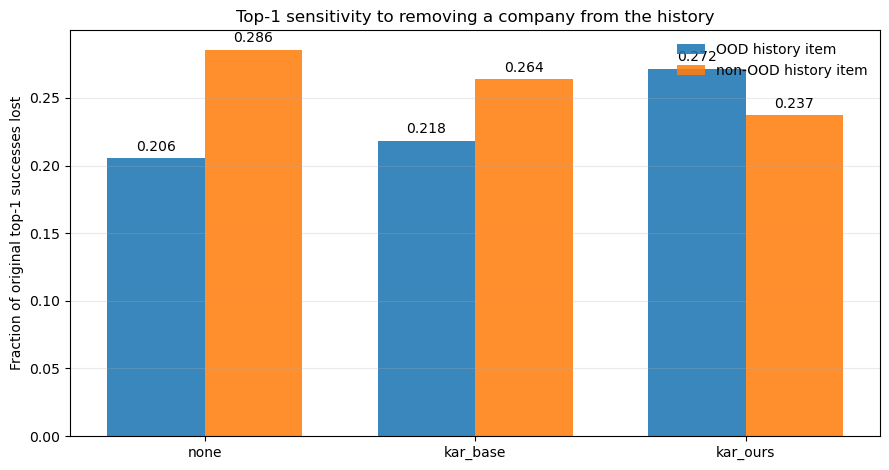

In [7]:
top1_rows = []
for adaptor in ADAPTORS:
    for group in ['OOD history item', 'non-OOD history item']:
        subset = results[(results.adaptor == adaptor) & (results.removed_item_group == group)]
        originally_correct = subset[subset.baseline_top1_correct.astype(str).str.lower() == 'true']
        lost = originally_correct.top1_success_lost.astype(str).str.lower() == 'true'
        top1_rows.append({
            'adaptor': adaptor,
            'removed_item_group': group,
            'originally_correct_removals': len(originally_correct),
            'top1_successes_lost': int(lost.sum()),
            'success_lost_rate': lost.mean() if len(lost) else np.nan,
        })
top1 = pd.DataFrame(top1_rows)
display(top1.set_index(['adaptor', 'removed_item_group']).round(5))

fig, axis = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(ADAPTORS))
for group_index, group in enumerate(['OOD history item', 'non-OOD history item']):
    values = [
        top1.loc[(top1.adaptor == adaptor) & (top1.removed_item_group == group), 'success_lost_rate'].iloc[0]
        for adaptor in ADAPTORS
    ]
    offsets = x + (group_index - 0.5) * bar_width
    bars = axis.bar(offsets, values, bar_width, label=group, alpha=0.88)
    axis.bar_label(bars, fmt='%.3f', padding=3)
axis.set_xticks(x, ADAPTORS)
axis.set_ylabel('Fraction of original top-1 successes lost')
axis.set_ylim(bottom=0)
axis.grid(axis='y', alpha=0.25)
axis.legend(frameon=False)
axis.set_title('Top-1 sensitivity to removing a company from the history')
fig.tight_layout()
plt.show()

## Interpretation cautions

- A larger positive attribution shows **model reliance**, not automatically better semantic understanding. Combine this result with Recall@K/AUC/logloss improvements and factual-embedding corruption tests.
- `kar_ours` uses the removed company through both DIN behavior attention and its recency-pooled company-history HEA stream. Its leave-one-out value therefore measures the company's **total effect through the existing architecture**.
- Removing all occurrences also removes their aligned tenure values and changes sequence length and recency weights. This measures company-level reliance, not a factual-vector-only effect.
- Company removals from one user are correlated observations. Formal confidence intervals or tests should bootstrap/cluster by user (or source row), not treat every company ablation as independent.
- Set `EXCLUDE_REMOVED_EQUALS_TARGET = True` to remove exact-repeat cases and focus on transfer between different companies.